In [8]:
!pip install spacy
!python -m spacy download en_core_web_sm


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\ADMIN\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip



Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---- ----------------------------------- 1.6/12.8 MB 10.5 MB/s eta 0:00:02
     --------- ------------------------------ 3.1/12.8 MB 9.7 MB/s eta 0:00:01
     ---------------- ----------------------- 5.2/12.8 MB 9.1 MB/s eta 0:00:01
     ---------------------- ----------------- 7.3/12.8 MB 9.4 MB/s eta 0:00:01
     ------------------------------ --------- 9.7/12.8 MB 9.9 MB/s eta 0:00:01
     ----------------------------------- --- 11.8/12.8 MB 10.0 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 9.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [9]:
import pandas as pd
import spacy
import matplotlib.pyplot as plt

nlp = spacy.load("en_core_web_sm")

In [10]:
# Load real and fake news
real = pd.read_csv("True.csv")
fake = pd.read_csv("Fake.csv")

print("Real news articles:", len(real))
print("Fake news articles:", len(fake))

Real news articles: 21417
Fake news articles: 23481


In [11]:
# Analyse active and passive voice
def analyse_voice(data):
    text = data["text"].head(200).fillna("").astype(str)
    docs = list(nlp.pipe(text, batch_size=20))

    sentences = [s for doc in docs for s in doc.sents]

    passive = sum(
        1 for s in sentences
        if any(t.dep_ in ["nsubjpass", "csubjpass"] for t in s)
        or any(t.dep_ == "auxpass" for t in s)
    )

    active = sum(
        1 for s in sentences
        if any(t.dep_ in ["nsubj", "csubj"] for t in s)
        and not (
            any(t.dep_ in ["nsubjpass", "csubjpass"] for t in s)
            or any(t.dep_ == "auxpass" for t in s)
        )
    )

    return active, passive

In [12]:
# compare real and fake news
real_active, real_passive = analyse_voice(real)
fake_active, fake_passive = analyse_voice(fake)

result = pd.DataFrame({
    "News Type": ["Real News", "Fake News"],
    "Active Voice": [real_active, fake_active],
    "Passive Voice": [real_passive, fake_passive]
})

print(result)

   News Type  Active Voice  Passive Voice
0  Real News          2547            576
1  Fake News          3013            653


In [13]:
# calculate percentages
result["Active (%)"] = (
    result["Active Voice"] /
    (result["Active Voice"] + result["Passive Voice"]) * 100
).round(2)

result["Passive (%)"] = (
    result["Passive Voice"] /
    (result["Active Voice"] + result["Passive Voice"]) * 100
).round(2)

print(result)

   News Type  Active Voice  Passive Voice  Active (%)  Passive (%)
0  Real News          2547            576       81.56        18.44
1  Fake News          3013            653       82.19        17.81


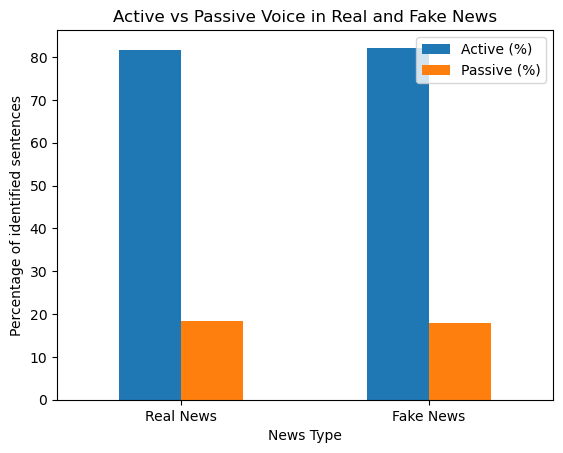

In [14]:
# visualise the results
result.plot(x="News Type", y=["Active (%)", "Passive (%)"], kind="bar")

plt.ylabel("Percentage of identified sentences")
plt.title("Active vs Passive Voice in Real and Fake News")
plt.xticks(rotation=0)
plt.show()